In [2]:
# 1. Import libraries

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from collections import Counter, defaultdict
from hashlib import sha256

sns.set_theme(style="whitegrid")

print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("Libraries imported successfully!")

PyTorch: 2.15.0
MPS available: True
Libraries imported successfully!


In [3]:
# 2. Load ScienceQA-IMG

dataset = load_dataset("lmms-lab/ScienceQA-IMG")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 6218
    })
    validation: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 2097
    })
    test: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 2017
    })
})


In [4]:
# 3. Dataset overview

for split in dataset:
    print(f"{split}: {len(dataset[split])} records")

print("\nColumns:")
print(dataset["train"].column_names)

print("\nSample question:")
print(dataset["train"][0]["question"])

print("\nAnswer options:")
print(dataset["train"][0]["choices"])

print("\nCorrect answer index:")
print(dataset["train"][0]["answer"])

train: 6218 records
validation: 2097 records
test: 2017 records

Columns:
['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution']

Sample question:
Which of these states is farthest north?

Answer options:
['West Virginia', 'Louisiana', 'Arizona', 'Oklahoma']

Correct answer index:
0


In [5]:
# 4. Convert dataset splits into DataFrames

train_df = dataset["train"].remove_columns(["image"]).to_pandas()
validation_df = dataset["validation"].remove_columns(["image"]).to_pandas()
test_df = dataset["test"].remove_columns(["image"]).to_pandas()

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (6218, 12)
Validation shape: (2097, 12)
Testing shape: (2017, 12)


Question: Which of these states is farthest north?

Answer choices:
A. West Virginia
B. Louisiana
C. Arizona
D. Oklahoma

Correct answer: West Virginia

Hint: No hint

Subject: social science
Grade: grade2


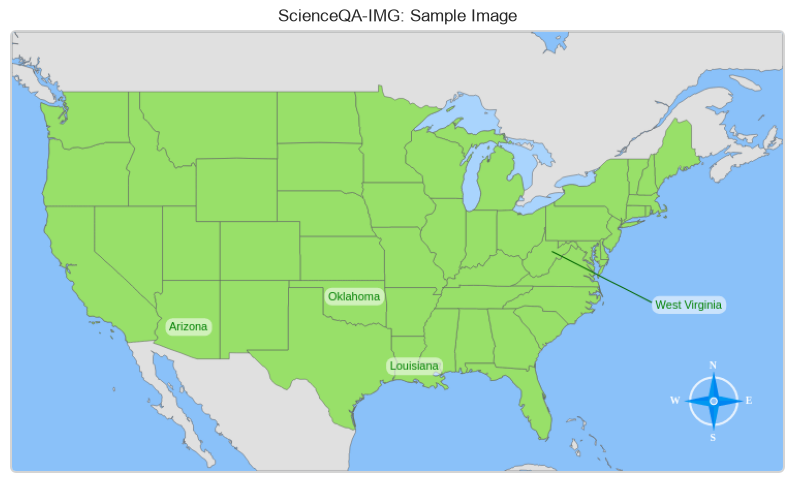

In [6]:

import matplotlib.pyplot as plt
import textwrap

sample = dataset["train"][0]

print("Question:", sample["question"])

print("\nAnswer choices:")
for i, choice in enumerate(sample["choices"]):
    print(f"{chr(65+i)}. {choice}")

print("\nCorrect answer:",
      sample["choices"][sample["answer"]])

print("\nHint:", sample["hint"] or "No hint")

print("\nSubject:", sample["subject"])
print("Grade:", sample["grade"])

plt.figure(figsize=(10, 6))
plt.imshow(sample["image"])
plt.axis("off")
plt.title("ScienceQA-IMG: Sample Image")
plt.show()


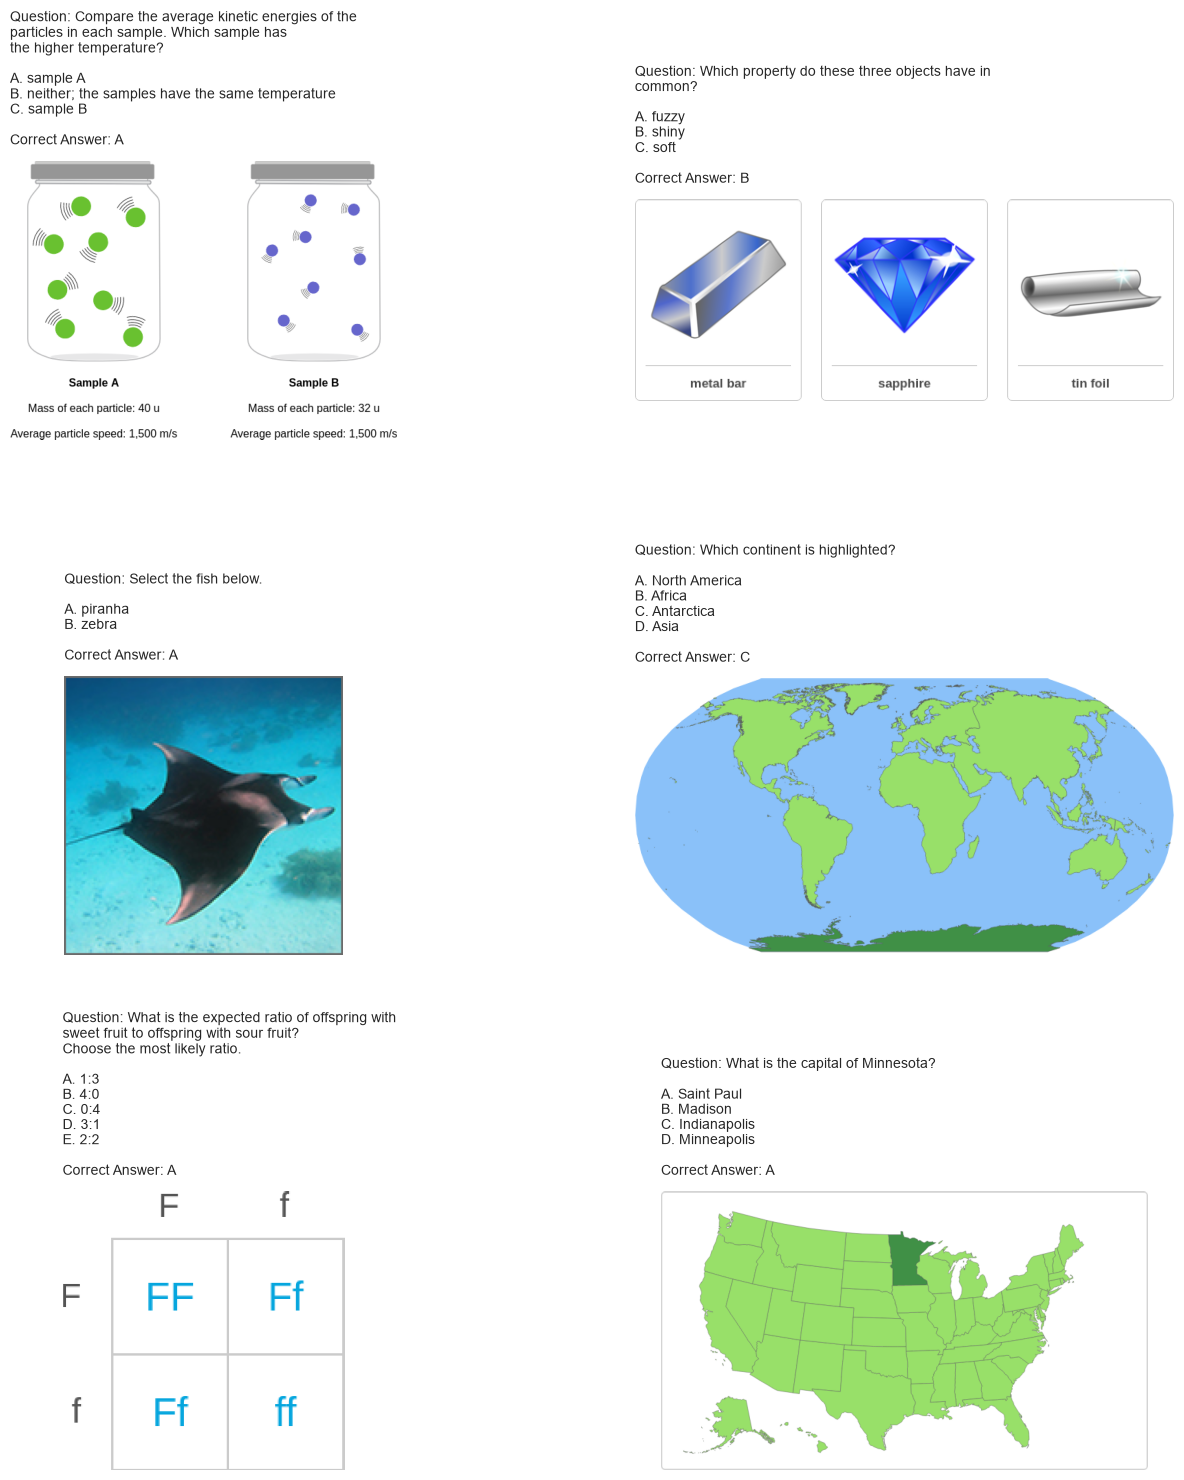

In [7]:

import matplotlib.pyplot as plt
import numpy as np
import textwrap

rng = np.random.default_rng(42)

indices = rng.choice(
    len(dataset["train"]),
    size=6,
    replace=False
)

fig, axes = plt.subplots(3, 2, figsize=(16, 17))

for ax, idx in zip(axes.flat, indices):
    sample = dataset["train"][int(idx)]

    ax.imshow(sample["image"])
    ax.axis("off")

    question = textwrap.fill(
        sample["question"], width=45
    )

    options = "\n".join(
        f"{chr(65+i)}. {choice}"
        for i, choice in enumerate(sample["choices"])
    )

    correct = chr(65 + sample["answer"])

    ax.set_title(
        f"Question: {question}\n\n"
        f"{options}\n\n"
        f"Correct Answer: {correct}",
        fontsize=10,
        loc="left",
        pad=12
    )

plt.subplots_adjust(hspace=0.85, wspace=0.3)
plt.show()


## Check missing values and data structure

In [8]:

import pandas as pd

quality_summary = []

for split_name in dataset:
    df = dataset[split_name].remove_columns(
        ["image"]
    ).to_pandas()

    quality_summary.append({
        "Split": split_name,
        "Records": len(df),
        "Missing Questions": df["question"].isna().sum(),
        "Missing Choices": df["choices"].isna().sum(),
        "Missing Answers": df["answer"].isna().sum(),
        "Blank Hints": (
            df["hint"].fillna("").str.strip() == ""
        ).sum(),
        "Missing Subjects": df["subject"].isna().sum()
    })

quality_df = pd.DataFrame(quality_summary)
display(quality_df)



,Split,Records,Missing Questions,Missing Choices,Missing Answers,Blank Hints,Missing Subjects
0,train,6218,0,0,0,2274,0
1,validation,2097,0,0,0,766,0
2,test,2017,0,0,0,760,0


## Check image integrity
We need to confirm that images can be decoded and understand their dimensions.

In [9]:

from collections import Counter

image_dimensions = Counter()
invalid_images = []

for split_name in dataset:
    for idx, sample in enumerate(dataset[split_name]):
        try:
            image = sample["image"].convert("RGB")
            image_dimensions[image.size] += 1
        except Exception:
            invalid_images.append((split_name, idx))

print("Number of unique image dimensions:",
      len(image_dimensions))

print("\nMost common image dimensions:")
for dimensions, count in image_dimensions.most_common(10):
    print(dimensions, ":", count)

print("\nInvalid images:", len(invalid_images))


Number of unique image dimensions: 727

Most common image dimensions:
(750, 429) : 1925
(162, 162) : 610
(202, 202) : 602
(302, 232) : 585
(452, 595) : 398
(704, 358) : 344
(252, 192) : 278
(750, 625) : 274
(312, 237) : 238
(728, 174) : 198

Invalid images: 0


## Check data leakage between splits

In [10]:

import hashlib
import io

def get_image_hash(image):
    buffer = io.BytesIO()
    image.convert("RGB").save(buffer, format="PNG")
    return hashlib.sha256(buffer.getvalue()).hexdigest()

image_hashes = {}

for split_name in dataset:
    hashes = []

    for sample in dataset[split_name]:
        hashes.append(get_image_hash(sample["image"]))

    image_hashes[split_name] = hashes

print("Image hashing completed.")


Image hashing completed.


## Compare image overlap

In [11]:

split_sets = {
    split: set(hashes)
    for split, hashes in image_hashes.items()
}

for split in ["train", "validation", "test"]:
    print(
        split,
        "records:", len(image_hashes[split]),
        "unique images:", len(split_sets[split])
    )

print("\nCross-split image overlap:")

for split_a, split_b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = split_sets[split_a] & split_sets[split_b]

    print(
        f"{split_a} vs {split_b}:",
        len(overlap), "shared images"
    )


train records: 6218 unique images: 4985
validation records: 2097 unique images: 1850
test records: 2017 unique images: 1799

Cross-split image overlap:
train vs validation: 390 shared images
train vs test: 389 shared images
validation vs test: 198 shared images


## Check identical questions and options

In [12]:

import json
import re
import hashlib

def normalise_text(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()

text_hashes = {}

for split_name in dataset:
    hashes = []

    for sample in dataset[split_name]:
        text_content = {
            "question": normalise_text(sample["question"]),
            "choices": [
                normalise_text(choice)
                for choice in sample["choices"]
            ]
        }

        content = json.dumps(
            text_content,
            sort_keys=True
        )

        hashes.append(
            hashlib.sha256(content.encode()).hexdigest()
        )

    text_hashes[split_name] = hashes

text_sets = {
    split: set(hashes)
    for split, hashes in text_hashes.items()
}

print("Identical question-and-option overlap:")

for split_a, split_b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = text_sets[split_a] & text_sets[split_b]

    print(
        f"{split_a} vs {split_b}:",
        len(overlap), "shared records"
    )


Identical question-and-option overlap:
train vs validation: 160 shared records
train vs test: 160 shared records
validation vs test: 101 shared records


## Cross-Split Data Leakage Analysis

This section identifies identical images and identical question-option combinations appearing across the training, validation and test datasets.

Calculate image overlap

In [13]:
all_image_hashes = set.union(*split_sets.values())

shared_image_hashes = {
    h for h in all_image_hashes
    if sum(h in split_sets[s] for s in split_sets) > 1
}

triple_shared_images = (
    split_sets["train"]
    & split_sets["validation"]
    & split_sets["test"]
)

print("Total unique images:", len(all_image_hashes))
print("Images shared across splits:", len(shared_image_hashes))
print("Images shared across all three splits:",
      len(triple_shared_images))

Total unique images: 7803
Images shared across splits: 685
Images shared across all three splits: 146


Calculate text overlap

In [14]:
all_text_hashes = set.union(*text_sets.values())

shared_text_hashes = {
    h for h in all_text_hashes
    if sum(h in text_sets[s] for s in text_sets) > 1
}

triple_shared_text = (
    text_sets["train"]
    & text_sets["validation"]
    & text_sets["test"]
)

print("Total unique question-option combinations:",
      len(all_text_hashes))

print("Combinations shared across splits:",
      len(shared_text_hashes))

print("Combinations shared across all three splits:",
      len(triple_shared_text))

Total unique question-option combinations: 8186
Combinations shared across splits: 243
Combinations shared across all three splits: 89


In [15]:

import hashlib

question_hashes = {}

for split_name in dataset:
    hashes = []

    for sample in dataset[split_name]:
        question = normalise_text(sample["question"])

        hashes.append(
            hashlib.sha256(question.encode()).hexdigest()
        )

    question_hashes[split_name] = hashes

question_sets = {
    split: set(hashes)
    for split, hashes in question_hashes.items()
}

print("Identical question text overlap:")

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    print(
        f"{a} vs {b}:",
        len(question_sets[a] & question_sets[b])
    )


Identical question text overlap:
train vs validation: 332
train vs test: 324
validation vs test: 239



## Cross-Split Data Cleaning

To reduce potential data leakage, exact image and question-text overlaps are removed across dataset splits.

The test set is retained as the reference split. Overlapping records are removed from validation, followed by training.

Duplicates within individual splits are preserved.


In [16]:

# 1. Keep the complete test set

clean_test = dataset["test"]

test_images = set(image_hashes["test"])
test_texts = set(text_hashes["test"])


# 2. Clean validation against test

val_keep_indices = [
    i for i, (img_hash, txt_hash) in enumerate(
        zip(image_hashes["validation"],
            text_hashes["validation"])
    )
    if img_hash not in test_images
    and txt_hash not in test_texts
]

clean_validation = dataset["validation"].select(
    val_keep_indices
)

validation_images = {
    image_hashes["validation"][i]
    for i in val_keep_indices
}

validation_texts = {
    text_hashes["validation"][i]
    for i in val_keep_indices
}


# 3. Clean training against test and validation

blocked_images = test_images | validation_images
blocked_texts = test_texts | validation_texts

train_keep_indices = [
    i for i, (img_hash, txt_hash) in enumerate(
        zip(image_hashes["train"], text_hashes["train"])
    )
    if img_hash not in blocked_images
    and txt_hash not in blocked_texts
]

clean_train = dataset["train"].select(
    train_keep_indices
)


# 4. Create cleaned dataset

from datasets import DatasetDict

clean_dataset = DatasetDict({
    "train": clean_train,
    "validation": clean_validation,
    "test": clean_test
})


# 5. Compare dataset sizes

for split in ["train", "validation", "test"]:
    original = len(dataset[split])
    cleaned = len(clean_dataset[split])

    print(
        f"{split.upper()}: {original} -> {cleaned} "
        f"(removed {original - cleaned})"
    )


clean_dataset.save_to_disk(
    "../data/processed/scienceqa_cleaned"
)

TRAIN: 6218 -> 3530 (removed 2688)
VALIDATION: 2097 -> 1343 (removed 754)
TEST: 2017 -> 2017 (removed 0)


Saving the dataset (0/1 shards):   0%|          | 0/3530 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1343 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2017 [00:00<?, ? examples/s]

In [17]:

# Verify no cross-split image or question-option overlap

clean_hashes = {}

for split in ["train", "validation", "test"]:
    indices = {
        "train": train_keep_indices,
        "validation": val_keep_indices,
        "test": list(range(len(dataset["test"])))
    }[split]

    clean_hashes[split] = {
        "images": {image_hashes[split][i] for i in indices},
        "texts": {text_hashes[split][i] for i in indices}
    }

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    print(f"\n{a.upper()} vs {b.upper()}")
    print("Image overlap:",
          len(clean_hashes[a]["images"] & clean_hashes[b]["images"]))
    print("Text overlap:",
          len(clean_hashes[a]["texts"] & clean_hashes[b]["texts"]))



TRAIN vs VALIDATION
Image overlap: 0
Text overlap: 0

TRAIN vs TEST
Image overlap: 0
Text overlap: 0

VALIDATION vs TEST
Image overlap: 0
Text overlap: 0



## 6. Distribution Analysis After Data Cleaning

This section compares the original and cleaned datasets to identify changes in subject, grade and answer-choice distributions resulting from cross-split duplicate removal.


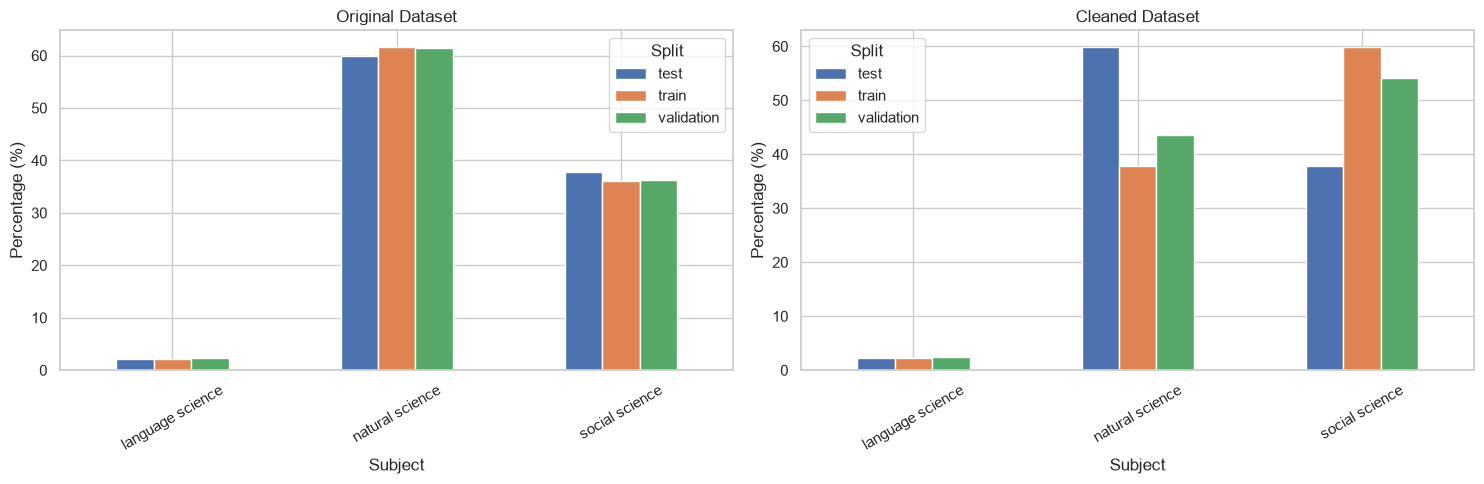

In [18]:

import pandas as pd
import matplotlib.pyplot as plt

def get_distribution(data, column):
    frames = []

    for split in ["train", "validation", "test"]:
        df = data[split].remove_columns(["image"]).to_pandas()

        counts = df[column].value_counts(normalize=True) * 100

        for category, percentage in counts.items():
            frames.append({
                "Split": split,
                "Category": category,
                "Percentage": percentage
            })

    return pd.DataFrame(frames)

original_subjects = get_distribution(dataset, "subject")
clean_subjects = get_distribution(clean_dataset, "subject")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, data, title in zip(
    axes,
    [original_subjects, clean_subjects],
    ["Original Dataset", "Cleaned Dataset"]
):
    pivot = data.pivot(
        index="Category",
        columns="Split",
        values="Percentage"
    ).fillna(0)

    pivot.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("Subject")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


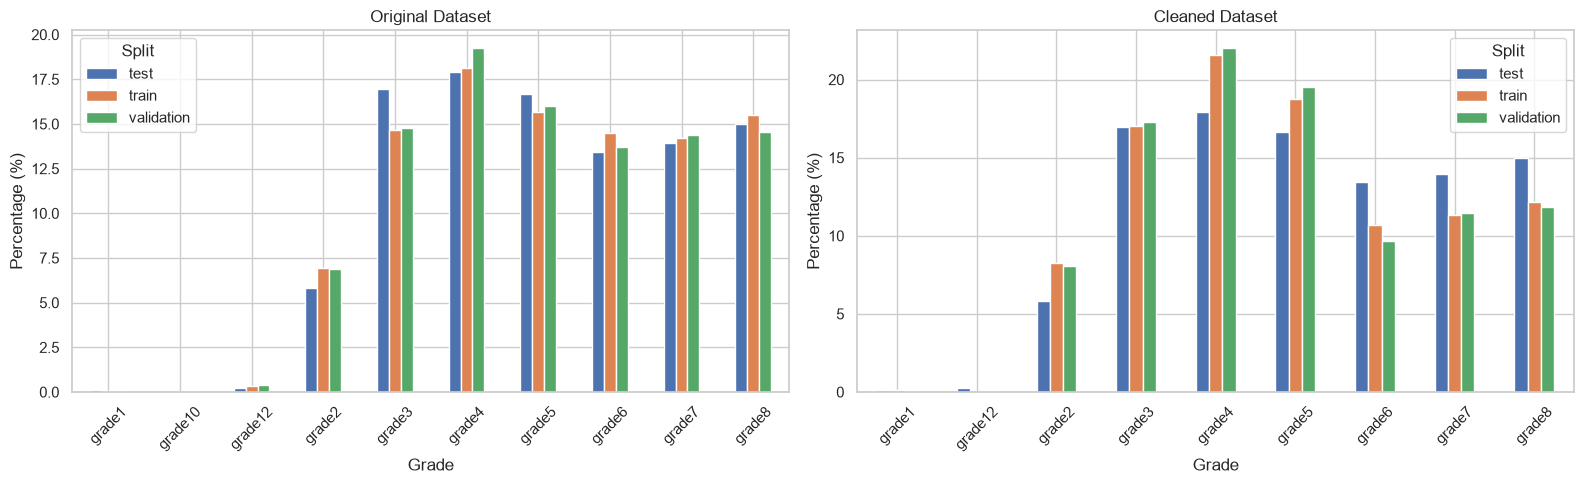

In [19]:

original_grades = get_distribution(dataset, "grade")
clean_grades = get_distribution(clean_dataset, "grade")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, data, title in zip(
    axes,
    [original_grades, clean_grades],
    ["Original Dataset", "Cleaned Dataset"]
):
    pivot = data.pivot(
        index="Category",
        columns="Split",
        values="Percentage"
    ).fillna(0)

    pivot.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("Grade")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [20]:

def get_choice_distribution(data):
    results = []

    for split in ["train", "validation", "test"]:
        df = data[split].remove_columns(["image"]).to_pandas()

        counts = df["choices"].apply(len).value_counts(normalize=True) * 100

        for n, percentage in counts.items():
            results.append({
                "Split": split,
                "Number of choices": n,
                "Percentage": percentage
            })

    return pd.DataFrame(results)

choice_distribution = get_choice_distribution(clean_dataset)

display(
    choice_distribution.pivot(
        index="Number of choices",
        columns="Split",
        values="Percentage"
    ).fillna(0).round(2)
)


Split,test,train,validation
Number of choices,,,
2,33.56,19.94,25.17
3,26.38,19.89,19.66
4,38.18,59.07,53.31
5,1.88,1.10,1.86
